In [ ]:
import pandas as pd
import numpy as np
import os
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving y_test.csv to y_test.csv
Saving X_train.csv to X_train.csv
Saving X_test.csv to X_test.csv
Saving X_validation.csv to X_validation.csv


In [ ]:
X_train = pd.read_csv('X_train.csv')
X_validation = pd.read_csv('X_validation.csv')
X_test = pd.read_csv('X_test.csv')
y_test = pd.read_csv('y_test.csv')

print("All CSV files loaded successfully!")

All CSV files loaded successfully!


In [ ]:
print("Training Data:", X_train.shape)
print("Validation Data:", X_validation.shape)
print("Testing Data:", X_test.shape)
print("Testing Labels:", y_test.shape)

Training Data: (728, 34)
Validation Data: (183, 34)
Testing Data: (507, 34)
Testing Labels: (507, 1)


In [ ]:
print("Missing Values:")
print("Training:", X_train.isnull().sum().sum())
print("Validation:", X_validation.isnull().sum().sum())
print("Testing:", X_test.isnull().sum().sum())
print("Labels:", y_test.isnull().sum().sum())

print("\nDuplicate Rows:")
print("Training:", X_train.duplicated().sum())
print("Validation:", X_validation.duplicated().sum())
print("Testing:", X_test.duplicated().sum())

print("\nFeature Columns Match:")
print(list(X_train.columns) == list(X_validation.columns) == list(X_test.columns))

print("\nTest Label Distribution:")
print(y_test.iloc[:, 0].value_counts())

Missing Values:
Training: 0
Validation: 0
Testing: 0
Labels: 0

Duplicate Rows:
Training: 0
Validation: 0
Testing: 0

Feature Columns Match:
True

Test Label Distribution:
label
1    407
0    100
Name: count, dtype: int64


In [ ]:
print("Training Data Types:")
print(X_train.dtypes.value_counts())

print("\nNon-Numeric Columns:")
print(X_train.select_dtypes(exclude=['number']).columns.tolist())

print("\nInfinite Values:")
print("Training:", np.isinf(X_train).sum().sum())
print("Validation:", np.isinf(X_validation).sum().sum())
print("Testing:", np.isinf(X_test).sum().sum())

Training Data Types:
float64    34
Name: count, dtype: int64

Non-Numeric Columns:
[]

Infinite Values:
Training: 0
Validation: 0
Testing: 0


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_validation_scaled = scaler.transform(X_validation)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("\nTraining Data:", X_train_scaled.shape)
print("Validation Data:", X_validation_scaled.shape)
print("Testing Data:", X_test_scaled.shape)

Feature scaling completed successfully!

Training Data: (728, 34)
Validation Data: (183, 34)
Testing Data: (507, 34)


In [ ]:
model = OneClassSVM(
    kernel='rbf',
    gamma='scale',
    nu=0.05
)

model.fit(X_train_scaled)

print("One-Class SVM model trained successfully!")

One-Class SVM model trained successfully!


In [ ]:
validation_scores = model.decision_function(X_validation_scaled)

validation_anomaly_scores = -validation_scores

print("Validation anomaly scores calculated successfully!")

print("\nFirst 10 Anomaly Scores:")
print(validation_anomaly_scores[:10])

Validation anomaly scores calculated successfully!

First 10 Anomaly Scores:
[ 1.07318851 -0.46638673 -0.51108778 -0.32019239 -0.11513623 -0.24837203
 -0.48183741 -0.10805316 -0.35361063 -0.2135193 ]


In [ ]:
threshold = np.percentile(validation_anomaly_scores, 95)

print("Selected Anomaly Threshold:", threshold)

Selected Anomaly Threshold: 0.3335512494150363


In [ ]:
test_scores = model.decision_function(X_test_scaled)

test_anomaly_scores = -test_scores

y_pred = (test_anomaly_scores > threshold).astype(int)

print("Predictions completed successfully!")

print("\nFirst 20 Predictions:")
print(y_pred[:20])

print("\nPredicted Class Distribution:")
print(pd.Series(y_pred).value_counts())

Predictions completed successfully!

First 20 Predictions:
[0 0 1 1 1 1 0 0 0 0 0 0 1 1 1 0 1 1 0 0]

Predicted Class Distribution:
0    325
1    182
Name: count, dtype: int64


In [ ]:
y_true = y_test.iloc[:, 0].values

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print("One-Class SVM Evaluation Results")

print("\nAccuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['Normal', 'Anomaly']))

One-Class SVM Evaluation Results

Accuracy: 0.52465483234714
Precision: 0.9560439560439561
Recall: 0.4275184275184275
F1 Score: 0.5908319185059423

Confusion Matrix:
[[ 92   8]
 [233 174]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.28      0.92      0.43       100
     Anomaly       0.96      0.43      0.59       407

    accuracy                           0.52       507
   macro avg       0.62      0.67      0.51       507
weighted avg       0.82      0.52      0.56       507



In [ ]:
roc_auc = roc_auc_score(y_true, test_anomaly_scores)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.731941031941032


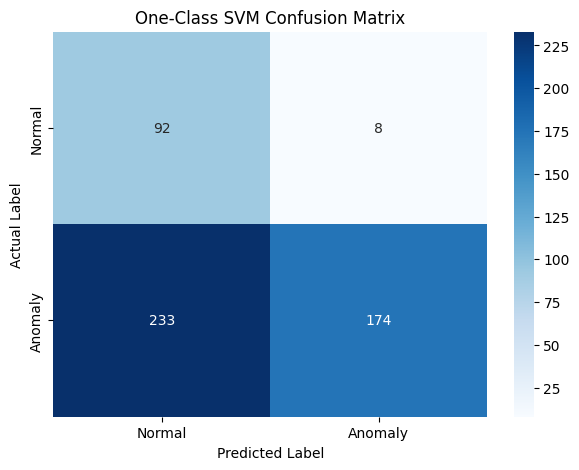

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Anomaly'],
    yticklabels=['Normal', 'Anomaly']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('One-Class SVM Confusion Matrix')
plt.show()

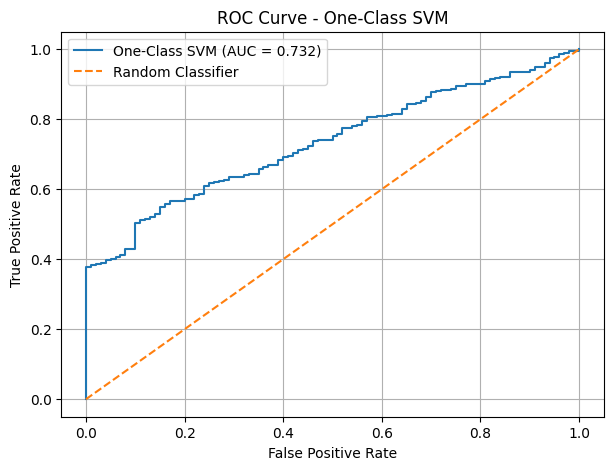

In [ ]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_true, test_anomaly_scores)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label='One-Class SVM (AUC = %.3f)' % roc_auc)
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - One-Class SVM')
plt.legend()
plt.grid()
plt.show()

In [ ]:
feature_names = X_train.columns.tolist()

joblib.dump(model, 'one_class_svm.pkl')
joblib.dump(scaler, 'scaler_svm.pkl')
joblib.dump(threshold, 'threshold_svm.pkl')
joblib.dump(feature_names, 'feature_names.pkl')

print("All model files saved successfully!")

All model files saved successfully!


In [ ]:
from google.colab import files

files.download('one_class_svm.pkl')
files.download('scaler_svm.pkl')
files.download('threshold_svm.pkl')
files.download('feature_names.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
results_df = pd.DataFrame({
    'Model': ['One-Class SVM'],
    'Accuracy': [accuracy],
    'Precision': [precision],
    'Recall': [recall],
    'F1 Score': [f1],
    'ROC-AUC': [roc_auc],
    'Threshold': [threshold]
})

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Threshold
0,One-Class SVM,0.524655,0.956044,0.427518,0.590832,0.731941,0.333551


In [ ]:
results_df.to_csv('Aamna_OneClassSVM_Results.csv', index=False)

from google.colab import files
files.download('Aamna_OneClassSVM_Results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

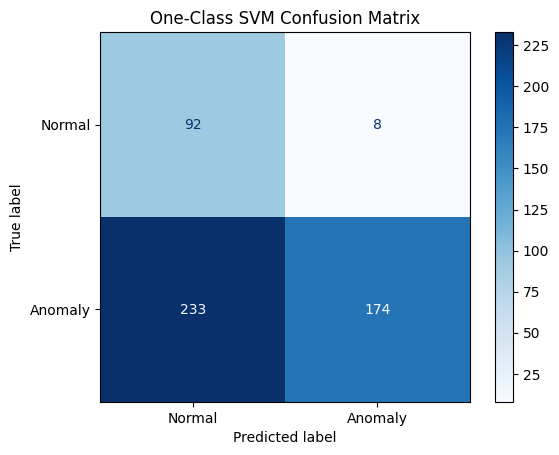

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Normal', 'Anomaly']
)

disp.plot(cmap='Blues')

plt.title('One-Class SVM Confusion Matrix')
plt.savefig('Aamna_Confusion_Matrix.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
files.download('Aamna_Confusion_Matrix.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

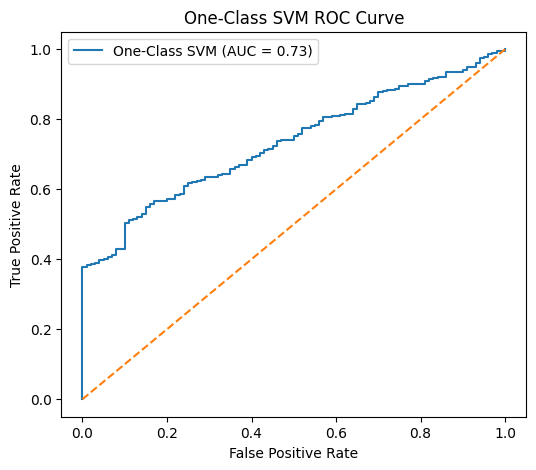

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_true, test_anomaly_scores)

roc_auc = roc_auc_score(y_true, test_anomaly_scores)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'One-Class SVM (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('One-Class SVM ROC Curve')
plt.legend()

plt.savefig('OneClassSVM_ROC_Curve.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
files.download('OneClassSVM_ROC_Curve.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
import joblib
import pandas as pd
import numpy as np

model = joblib.load('one_class_svm.pkl')
scaler = joblib.load('scaler_svm.pkl')

X_test = pd.read_csv('X_test.csv')

print("SVM model loaded!")
print("Scaler loaded!")
print("Test data shape:", X_test.shape)

SVM model loaded!
Scaler loaded!
Test data shape: (507, 34)


In [4]:

X_test_scaled = scaler.transform(X_test)

test_scores = model.decision_function(X_test_scaled)

test_anomaly_scores = -test_scores

print("SVM anomaly scores generated:", len(test_anomaly_scores))
print("First 5 scores:", test_anomaly_scores[:5])


SVM anomaly scores generated: 507
First 5 scores: [-0.28226639 -0.62460527  1.29259718  1.2923785   1.29258157]


In [5]:
np.save('SVM_Test_Anomaly_Scores.npy', test_anomaly_scores)

print("SVM anomaly scores saved successfully!")

SVM anomaly scores saved successfully!
